# Учень SmallCNN: без дистиляції та з дистиляцією, 200 епох (AID, варіант 3)

Мета — з'ясувати **межі** компактного учня: що він досягає при довгому навчанні (200 епох) звичайним способом
і з дистиляцією знань.

* **student** — SmallCNN з нуля, cross-entropy за мітками;
* **student_kd** — такий самий SmallCNN, втрата Хінтона: $\alpha T^2 \mathrm{KL}(p_t^T \| p_s^T) + (1-\alpha)\mathrm{CE}$,
  учитель — ResNet18 після fine-tuning (`exp5_finetune`), **T = 4, α = 0.7**.

Обидва учні мають однакові початкові ваги, бюджет (200 епох, AdamW + OneCycle), аугментацію та порядок батчів —
відрізняється лише функція втрат. Найкраща епоха обирається за validation, фінальні метрики — на test.

## 0. Налаштування

In [1]:
import os, io, json, time, random, copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, TensorDataset
from torchvision import models
from torchvision.transforms.v2 import functional as TF
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support, confusion_matrix

SEED = 42
IMG_SIZE = 224                 # стандартний вхід для моделей, навчених на ImageNet
BATCH_SIZE = 64
EPOCHS_ST = 200                # бюджет навчання — однаковий для обох учнів
LR_ST = 3e-3                   # max LR для OneCycle (учень навчається з нуля)
WEIGHT_DECAY = 5e-4
KD_T, KD_ALPHA = 4.0, 0.7      # температура і вага дистиляційної складової
TEACHER = 'exp5_finetune'      # ResNet18 після fine-tuning layer4
PRINT_EVERY = 10               # як часто друкувати прогрес навчання
BLUR_SIGMA = (0.5, 1.2)        # «легке» розмиття: sigma гаусового ядра 5×5
NUM_WORKERS = min(4, os.cpu_count())
MP_CONTEXT = 'fork' if NUM_WORKERS > 0 else None   # воркери бачать кеш зображень у RAM без копіювання

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = device.type == 'cuda'
OUT_DIR = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('outputs')
OUT_DIR.mkdir(parents=True, exist_ok=True)
print('device:', device, torch.cuda.get_device_name(0) if device.type == 'cuda' else '')
print('outputs ->', OUT_DIR)


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed()

device: cuda Tesla T4
outputs -> /kaggle/working


## 1. Дані та поділ

In [2]:
VAL_TEST = {   # клас: ([номери файлів val], [номери файлів test])
    'Airport': ([20, 22, 23, 54, 125, 154, 202, 236, 238, 244, 256, 294, 297, 306, 309],
               [1, 29, 38, 46, 47, 85, 91, 97, 190, 206, 223, 231, 234, 251, 262, 278, 311, 314, 329, 345]),
    'BareLand': ([57, 58, 73, 96, 98, 104, 112, 154, 181, 205, 232, 236, 245, 273, 303],
                [2, 5, 40, 60, 62, 63, 77, 109, 115, 120, 146, 163, 167, 187, 192, 217, 221, 231, 267, 282]),
    'BaseballField': ([3, 13, 14, 36, 74, 86, 98, 132, 135, 145, 149, 153, 180, 183, 197],
                     [10, 26, 40, 53, 55, 58, 80, 119, 129, 131, 147, 173, 175, 178, 187, 188, 198, 205, 211, 217]),
    'Beach': ([11, 28, 43, 93, 107, 126, 136, 180, 269, 274, 286, 293, 321, 341, 381],
             [3, 64, 72, 77, 128, 134, 142, 153, 161, 171, 175, 246, 275, 279, 280, 292, 310, 313, 316, 333]),
    'Bridge': ([64, 66, 90, 124, 135, 141, 161, 168, 207, 210, 211, 216, 225, 275, 350],
              [33, 35, 40, 49, 52, 55, 74, 139, 150, 151, 159, 181, 192, 198, 247, 256, 301, 338, 340, 352]),
    'Center': ([35, 47, 55, 62, 79, 83, 156, 158, 170, 171, 208, 222, 228, 239, 240],
              [11, 14, 21, 37, 53, 61, 103, 106, 164, 168, 174, 182, 202, 204, 214, 218, 223, 232, 235, 251]),
    'Church': ([26, 47, 49, 71, 80, 82, 97, 114, 117, 125, 160, 187, 203, 209, 233],
              [3, 7, 9, 20, 28, 51, 53, 58, 63, 70, 74, 78, 99, 151, 175, 197, 199, 234, 237, 240]),
    'Commercial': ([9, 29, 106, 116, 133, 168, 182, 211, 218, 231, 282, 287, 318, 349, 350],
                  [2, 21, 33, 87, 122, 124, 130, 132, 140, 162, 185, 201, 223, 235, 255, 273, 307, 322, 332, 342]),
    'DenseResidential': ([8, 19, 29, 41, 66, 88, 153, 172, 263, 265, 275, 318, 332, 365, 399],
                        [10, 46, 54, 57, 60, 63, 68, 76, 83, 100, 110, 111, 113, 188, 190, 197, 249, 259, 294, 335]),
    'Desert': ([12, 35, 71, 98, 126, 202, 223, 237, 243, 244, 270, 283, 290, 293, 299],
              [23, 44, 54, 64, 69, 73, 90, 121, 138, 144, 152, 185, 186, 231, 255, 256, 266, 279, 289, 292]),
    'Farmland': ([86, 114, 123, 188, 192, 194, 199, 213, 221, 228, 232, 271, 341, 352, 355],
                [3, 21, 43, 100, 155, 195, 201, 208, 215, 217, 220, 226, 236, 253, 270, 273, 290, 320, 329, 336]),
    'Forest': ([3, 22, 37, 40, 70, 75, 112, 114, 141, 149, 197, 198, 221, 224, 235],
              [1, 4, 10, 23, 26, 29, 56, 58, 87, 101, 130, 131, 137, 161, 163, 168, 172, 185, 200, 213]),
    'Industrial': ([19, 23, 55, 56, 117, 128, 131, 138, 145, 151, 232, 279, 293, 350, 376],
                  [11, 13, 24, 25, 32, 48, 62, 64, 92, 123, 130, 143, 178, 217, 225, 228, 303, 308, 309, 330]),
    'Meadow': ([3, 15, 30, 32, 102, 115, 116, 136, 154, 166, 204, 208, 210, 217, 231],
              [2, 27, 45, 46, 49, 93, 105, 119, 122, 126, 129, 147, 193, 197, 198, 211, 241, 251, 257, 273]),
    'MediumResidential': ([4, 6, 14, 19, 37, 67, 75, 116, 119, 125, 180, 182, 188, 238, 249],
                         [1, 3, 5, 8, 11, 13, 15, 22, 24, 29, 109, 114, 130, 163, 202, 205, 207, 210, 284, 289]),
    'Mountain': ([6, 12, 22, 29, 40, 50, 70, 91, 117, 132, 145, 175, 206, 239, 310],
                [11, 16, 20, 24, 51, 54, 98, 101, 119, 137, 142, 146, 154, 166, 185, 190, 218, 225, 237, 336]),
    'Park': ([3, 7, 32, 39, 82, 126, 127, 176, 192, 249, 256, 269, 284, 304, 322],
            [1, 2, 33, 54, 57, 83, 105, 112, 129, 168, 184, 201, 225, 228, 288, 289, 310, 311, 321, 345]),
    'Parking': ([2, 109, 117, 140, 144, 165, 215, 273, 282, 284, 287, 302, 336, 341, 377],
               [7, 21, 94, 98, 110, 148, 167, 169, 184, 204, 210, 214, 219, 230, 257, 275, 290, 345, 354, 386]),
    'Playground': ([6, 32, 65, 90, 109, 133, 151, 174, 214, 222, 250, 255, 283, 299, 356],
                  [25, 41, 43, 53, 72, 75, 111, 112, 116, 122, 178, 202, 224, 280, 296, 304, 321, 343, 349, 364]),
    'Pond': ([58, 69, 121, 165, 174, 181, 182, 186, 193, 200, 223, 276, 331, 392, 419],
            [13, 16, 30, 102, 105, 145, 160, 167, 180, 204, 211, 220, 231, 251, 280, 324, 371, 382, 396, 418]),
    'Port': ([3, 22, 30, 38, 51, 63, 64, 94, 137, 158, 161, 168, 205, 264, 292],
            [75, 79, 92, 99, 104, 173, 195, 200, 220, 231, 235, 237, 251, 269, 298, 303, 309, 334, 340, 375]),
    'RailwayStation': ([18, 29, 36, 39, 56, 91, 94, 143, 149, 150, 151, 174, 194, 242, 250],
                      [6, 25, 41, 43, 61, 63, 69, 75, 87, 96, 109, 114, 135, 141, 154, 161, 170, 217, 228, 240]),
    'Resort': ([67, 104, 123, 124, 134, 138, 175, 184, 201, 255, 273, 275, 279, 283, 285],
              [11, 14, 76, 91, 114, 130, 132, 162, 163, 178, 191, 200, 207, 220, 226, 228, 246, 249, 281, 287]),
    'River': ([33, 76, 111, 161, 240, 292, 303, 307, 324, 331, 334, 347, 349, 375, 386],
             [38, 44, 64, 86, 125, 156, 208, 212, 229, 244, 255, 259, 264, 298, 313, 327, 344, 360, 366, 389]),
    'School': ([6, 12, 69, 94, 114, 137, 160, 164, 168, 171, 187, 191, 222, 235, 246],
              [17, 18, 19, 39, 84, 96, 108, 130, 132, 146, 152, 205, 207, 224, 227, 284, 286, 287, 290, 299]),
    'SparseResidential': ([16, 19, 34, 52, 76, 81, 112, 113, 134, 152, 160, 178, 235, 278, 285],
                         [1, 23, 27, 44, 54, 58, 62, 69, 78, 91, 92, 125, 126, 136, 141, 145, 179, 228, 241, 289]),
    'Square': ([45, 53, 68, 106, 112, 115, 117, 179, 205, 209, 250, 312, 317, 321, 330],
              [13, 24, 46, 59, 90, 91, 148, 165, 187, 193, 196, 202, 212, 232, 271, 282, 284, 304, 314, 329]),
    'Stadium': ([5, 6, 60, 69, 97, 117, 121, 143, 176, 205, 228, 242, 262, 284, 289],
               [4, 9, 23, 26, 28, 29, 31, 58, 61, 132, 135, 141, 145, 180, 183, 190, 197, 226, 266, 276]),
    'StorageTanks': ([25, 41, 62, 67, 99, 172, 223, 256, 260, 282, 301, 321, 341, 347, 349],
                    [31, 34, 57, 69, 73, 105, 110, 141, 189, 204, 206, 216, 234, 245, 249, 317, 320, 351, 358, 359]),
    'Viaduct': ([27, 73, 112, 125, 126, 150, 190, 226, 241, 250, 299, 329, 339, 400, 416],
               [16, 32, 62, 90, 103, 123, 161, 168, 183, 191, 213, 214, 240, 265, 266, 269, 343, 348, 386, 397]),
}

In [3]:
def find_aid_root():
    # Папка, в якій лежать усі 30 папок-класів (беремо оригінальний AID, а не копії поділу)
    for base in (Path('data'), Path('../data'), Path('/kaggle/input')):
        if not base.exists():
            continue
        for p in sorted(base.rglob('Airport')):
            if p.is_dir() and all((p.parent / c).is_dir() for c in VAL_TEST) and 'AID_split' not in p.parts:
                return p.parent
    raise FileNotFoundError('Датасет AID не знайдено: завантажте його в data/ або підключіть як Kaggle input')


DATA_DIR = find_aid_root()
classes = sorted(VAL_TEST)
class_to_idx = {c: i for i, c in enumerate(classes)}
NUM_CLASSES = len(classes)

records = []
for c in classes:
    val_ids, test_ids = map(set, VAL_TEST[c])
    for f in sorted((DATA_DIR / c).glob('*.jpg')):
        n = int(f.stem.rsplit('_', 1)[1])
        split = 'val' if n in val_ids else 'test' if n in test_ids else 'train'
        records.append((str(f), c, class_to_idx[c], split))
df = pd.DataFrame(records, columns=['path', 'class', 'label', 'split'])

counts = pd.crosstab(df['class'], df['split'])
assert (counts['val'] == 15).all() and (counts['test'] == 20).all(), 'поділ не збігається з файлами датасету'
print('Папка з класами:', DATA_DIR)
print(f'Класів: {NUM_CLASSES}, зображень: {len(df)}', df['split'].value_counts().to_dict())

Папка з класами: /kaggle/input/datasets/jiayuanchengala/aid-scene-classification-datasets/AID
Класів: 30, зображень: 10000 {'train': 8950, 'test': 600, 'val': 450}


In [4]:
class PathDataset(Dataset):
    def __init__(self, paths):
        self.paths = list(paths)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        with Image.open(self.paths[i]) as im:
            im.draft('RGB', (IMG_SIZE, IMG_SIZE))   # JPEG декодується одразу в 300×300 — швидше
            im = im.convert('RGB').resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
        return torch.from_numpy(np.asarray(im).copy()).permute(2, 0, 1)   # HWC -> CHW, uint8


IMAGES = torch.empty((len(df), 3, IMG_SIZE, IMG_SIZE), dtype=torch.uint8)
LABELS = torch.tensor(df['label'].values, dtype=torch.long)
pos = 0
for batch in tqdm(DataLoader(PathDataset(df['path']), batch_size=128, num_workers=NUM_WORKERS,
                             multiprocessing_context=MP_CONTEXT), desc='Кешування'):
    IMAGES[pos:pos + len(batch)] = batch
    pos += len(batch)

idx = {s: np.where(df['split'] == s)[0] for s in ('train', 'val', 'test')}
print(IMAGES.shape, f'{IMAGES.numel() / 1024**3:.2f} GB')

Кешування:   0%|          | 0/79 [00:00<?, ?it/s]

torch.Size([10000, 3, 224, 224]) 1.40 GB


### Аугментація

У `__getitem__` для кожного навчального зображення випадково обирається одна з аугментацій: поворот на 90°/180°/270°,
горизонтальне чи вертикальне віддзеркалення або легке гаусове розмиття. Val/test — без аугментації.

In [5]:
AUG_OPS = ('rot90', 'flip', 'blur')


def augment(x, op):
    # x: uint8-тензор 3×H×W
    if op == 'rot90':
        return torch.rot90(x, int(torch.randint(1, 4, ())), dims=(1, 2))
    if op == 'flip':
        return x.flip(2) if torch.rand(()) < 0.5 else x.flip(1)   # горизонтальне / вертикальне
    if op == 'blur':
        sigma = float(torch.empty(()).uniform_(*BLUR_SIGMA))
        return TF.gaussian_blur(x, kernel_size=[5, 5], sigma=[sigma, sigma])
    raise ValueError(op)


class AIDDataset(Dataset):
    def __init__(self, indices, augment=False):
        self.indices = np.asarray(indices)
        self.augment = augment

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        j = self.indices[i]
        x = IMAGES[j]
        if self.augment:
            x = augment(x, AUG_OPS[int(torch.randint(len(AUG_OPS), ()))])
        return x, LABELS[j]


def make_loader(indices, augment=False, shuffle=False, seed=SEED):
    # Окремий генератор з тим самим seed -> однаковий порядок батчів (і аугментацій) у парних експериментах
    return DataLoader(AIDDataset(indices, augment), batch_size=BATCH_SIZE, shuffle=shuffle,
                      generator=torch.Generator().manual_seed(seed), num_workers=NUM_WORKERS,
                      multiprocessing_context=MP_CONTEXT, persistent_workers=NUM_WORKERS > 0,
                      pin_memory=device.type == 'cuda')


train_loader = make_loader(idx['train'], shuffle=True)
train_loader_aug = make_loader(idx['train'], augment=True, shuffle=True)
train_eval_loader = make_loader(idx['train'])          # train без аугментації — для оцінки перенавчання
val_loader = make_loader(idx['val'])
test_loader = make_loader(idx['test'])

## 2. Навчання та оцінка

In [6]:
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1) * 255
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1) * 255


def to_input(x):
    return (x.to(device, non_blocking=True).float() - IMAGENET_MEAN) / IMAGENET_STD


def build_resnet18(pretrained=True):
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
    return model


def freeze_backbone(model, trainable=('fc',)):
    for name, p in model.named_parameters():
        p.requires_grad = name.startswith(trainable)


def set_train_mode(model):
    # train() лише для шарів, що навчаються; заморожені BatchNorm лишаються в eval()
    model.train()
    for m in model.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm) and not any(p.requires_grad for p in m.parameters()):
            m.eval()


def count_params(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)

In [7]:
@torch.no_grad()
def predict(model, loader):
    model.eval()
    logits, labels = [], []
    for x, y in loader:
        with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
            logits.append(model(to_input(x)).float().cpu())
        labels.append(y)
    return torch.cat(logits), torch.cat(labels)


def metrics(logits, labels):
    pred = logits.argmax(1).numpy()
    return {'loss': F.cross_entropy(logits, labels).item(),
            'acc': accuracy_score(labels, pred),
            'f1': f1_score(labels, pred, average='macro')}


def fit(model, train_loader, name, epochs=EPOCHS_ST, lr=LR_ST, loss_fn=None):
    # Навчання учня з нуля: AdamW + OneCycle (крок scheduler-а — на кожному батчі).
    # loss_fn(logits, x, y) — за замовчуванням cross-entropy; для дистиляції передаємо KD-втрату.
    loss_fn = loss_fn or (lambda logits, x, y: F.cross_entropy(logits, y))
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(params, lr=lr, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=lr, epochs=epochs,
                                                    steps_per_epoch=len(train_loader), pct_start=0.15)
    scaler = torch.amp.GradScaler(enabled=USE_AMP)
    hist = {k: [] for k in ('train_loss', 'train_acc', 'val_loss', 'val_acc', 'val_f1')}
    best_acc, best_state, best_epoch = -1, None, 0
    t0 = time.time()

    for epoch in range(1, epochs + 1):
        set_train_mode(model)
        tot_loss, correct, n = 0.0, 0, 0
        for x, y in train_loader:
            x, y = to_input(x), y.to(device, non_blocking=True)
            with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(x)
                loss = loss_fn(logits, x, y)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            tot_loss += loss.item() * len(y)
            correct += (logits.argmax(1) == y).sum().item()
            n += len(y)

        val = metrics(*predict(model, val_loader))
        for k, v in (('train_loss', tot_loss / n), ('train_acc', correct / n),
                     ('val_loss', val['loss']), ('val_acc', val['acc']), ('val_f1', val['f1'])):
            hist[k].append(v)
        if val['acc'] > best_acc:   # вибір епохи — лише за validation
            best_acc, best_epoch = val['acc'], epoch
            best_state = copy.deepcopy(model.state_dict())
        if epoch == 1 or epoch % PRINT_EVERY == 0 or epoch == epochs:
            print(f'[{name}] epoch {epoch:3d}/{epochs}  train loss {tot_loss / n:.4f} acc {correct / n:.4f} | '
                  f'val loss {val["loss"]:.4f} acc {val["acc"]:.4f} f1 {val["f1"]:.4f}  ({time.time() - t0:.0f} s)')

    model.load_state_dict(best_state)
    torch.save(best_state, OUT_DIR / f'{name}.pt')
    hist.update(best_epoch=best_epoch, train_time=time.time() - t0)
    print(f'[{name}] найкраща епоха за val acc: {best_epoch} ({best_acc:.4f}), ваги -> {OUT_DIR / name}.pt')
    return hist


results, histories, test_preds = {}, {}, {}


def evaluate_model(model, name, hist):
    row = {'trainable_params': count_params(model, trainable_only=True), 'best_epoch': hist['best_epoch'],
           'train_time_s': round(hist['train_time'])}
    for split, loader in (('train', train_eval_loader), ('val', val_loader), ('test', test_loader)):
        logits, labels = predict(model, loader)
        m = metrics(logits, labels)
        row[f'{split}_acc'], row[f'{split}_f1'] = m['acc'], m['f1']
        if split == 'test':
            test_preds[name] = logits.argmax(1).numpy()
    row['train-val gap'] = row['train_acc'] - row['val_acc']
    results[name], histories[name] = row, hist
    return pd.DataFrame(row, index=[name]).round(4)

## 3. Модель учня та вчитель

In [8]:
def conv_bn(cin, cout, stride=1):
    return nn.Sequential(nn.Conv2d(cin, cout, 3, stride, 1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))


class SmallCNN(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        self.features = nn.Sequential(
            conv_bn(3, 32, stride=2), conv_bn(32, 32), nn.MaxPool2d(2),
            conv_bn(32, 64), conv_bn(64, 64), nn.MaxPool2d(2),
            conv_bn(64, 128), conv_bn(128, 128), nn.MaxPool2d(2),
            conv_bn(128, 256), conv_bn(256, 256),
        )
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, num_classes))

    def forward(self, x):
        return self.head(self.features(x))


set_seed()
student_init = SmallCNN().state_dict()
torch.save(student_init, OUT_DIR / 'student_init.pt')

print(f'Параметрів учня: {count_params(SmallCNN()):,}')

def new_student():
    model = SmallCNN()
    model.load_state_dict(student_init)
    return model.to(device)

Параметрів учня: 1,180,926


In [9]:
def find_prev(filename):
    for base in (Path('../step5/out'), Path('step5/out'), Path('/kaggle/input')):
        if base.exists():
            hits = sorted(base.rglob(filename))
            if hits:
                return hits[0]
    raise FileNotFoundError(f'{filename} не знайдено — підключіть вихід кернела lab2-aid-step5-finetune')


teacher = build_resnet18(pretrained=False)
teacher.load_state_dict(torch.load(find_prev(f'{TEACHER}.pt'), map_location='cpu'))
for p in teacher.parameters():
    p.requires_grad = False
teacher = teacher.to(device).eval()
print('Учитель:', TEACHER)

Учитель: exp5_finetune


## 4. Учень без дистиляції

In [10]:
results, histories, test_preds = {}, {}, {}
MODELS = {}

set_seed()
MODELS['student'] = new_student()
hist = fit(MODELS['student'], train_loader_aug, 'student')
evaluate_model(MODELS['student'], 'student', hist)

[student] epoch   1/200  train loss 2.4990 acc 0.3076 | val loss 2.2905 acc 0.3867 f1 0.3546  (9 s)
[student] epoch  10/200  train loss 0.9367 acc 0.7109 | val loss 1.7490 acc 0.5356 f1 0.5252  (67 s)
[student] epoch  20/200  train loss 0.4891 acc 0.8437 | val loss 1.2168 acc 0.6333 f1 0.6346  (136 s)
[student] epoch  30/200  train loss 0.3132 acc 0.8985 | val loss 2.0887 acc 0.5578 f1 0.5473  (206 s)
[student] epoch  40/200  train loss 0.2273 acc 0.9234 | val loss 0.7390 acc 0.7978 f1 0.7957  (275 s)
[student] epoch  50/200  train loss 0.1637 acc 0.9451 | val loss 1.0068 acc 0.7467 f1 0.7562  (344 s)
[student] epoch  60/200  train loss 0.1075 acc 0.9650 | val loss 0.6299 acc 0.8400 f1 0.8388  (413 s)
[student] epoch  70/200  train loss 0.0875 acc 0.9692 | val loss 0.7466 acc 0.8311 f1 0.8336  (483 s)
[student] epoch  80/200  train loss 0.0709 acc 0.9770 | val loss 0.6503 acc 0.8422 f1 0.8453  (552 s)
[student] epoch  90/200  train loss 0.0593 acc 0.9800 | val loss 0.7678 acc 0.8467 f1

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c9b19e19f80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process


,trainable_params,best_epoch,train_time_s,train_acc,train_f1,val_acc,val_f1,test_acc,test_f1,train-val gap
student,1180926,125,1380,0.9998,0.9998,0.9022,0.9025,0.9033,0.9026,0.0976


## 5. Учень із дистиляцією (T = 4, α = 0.7)

Учитель — у `eval()`, без градієнтів, отримує той самий аугментований батч, що й учень.

In [11]:
def make_kd_loss(teacher, T, alpha):
    teacher.eval()

    def kd_loss(logits, x, y):
        with torch.no_grad():
            t_logits = teacher(x)
        kd = F.kl_div(F.log_softmax(logits.float() / T, dim=1), F.softmax(t_logits.float() / T, dim=1),
                      reduction='batchmean') * T * T
        return alpha * kd + (1 - alpha) * F.cross_entropy(logits, y)

    return kd_loss


set_seed()
MODELS['student_kd'] = new_student()
hist = fit(MODELS['student_kd'], train_loader_aug, 'student_kd', loss_fn=make_kd_loss(teacher, KD_T, KD_ALPHA))
evaluate_model(MODELS['student_kd'], 'student_kd', hist)

[student_kd] epoch   1/200  train loss 18.9460 acc 0.2616 | val loss 2.4202 acc 0.2978 f1 0.2427  (11 s)
[student_kd] epoch  10/200  train loss 6.2778 acc 0.7189 | val loss 1.7771 acc 0.6178 f1 0.6096  (110 s)
[student_kd] epoch  20/200  train loss 3.3776 acc 0.8740 | val loss 1.0800 acc 0.7644 f1 0.7643  (220 s)
[student_kd] epoch  30/200  train loss 2.5262 acc 0.9208 | val loss 1.1280 acc 0.7622 f1 0.7587  (329 s)
[student_kd] epoch  40/200  train loss 2.0903 acc 0.9470 | val loss 0.8737 acc 0.7933 f1 0.7958  (438 s)
[student_kd] epoch  50/200  train loss 1.8163 acc 0.9591 | val loss 0.6649 acc 0.8378 f1 0.8361  (547 s)
[student_kd] epoch  60/200  train loss 1.6318 acc 0.9696 | val loss 0.5255 acc 0.8667 f1 0.8670  (656 s)
[student_kd] epoch  70/200  train loss 1.4687 acc 0.9789 | val loss 0.4760 acc 0.8756 f1 0.8749  (765 s)
[student_kd] epoch  80/200  train loss 1.3521 acc 0.9823 | val loss 0.4863 acc 0.8711 f1 0.8721  (874 s)
[student_kd] epoch  90/200  train loss 1.2185 acc 0.988

,trainable_params,best_epoch,train_time_s,train_acc,train_f1,val_acc,val_f1,test_acc,test_f1,train-val gap
student_kd,1180926,122,2182,0.9991,0.9991,0.9244,0.9247,0.9017,0.9005,0.0747


## 6. Результати

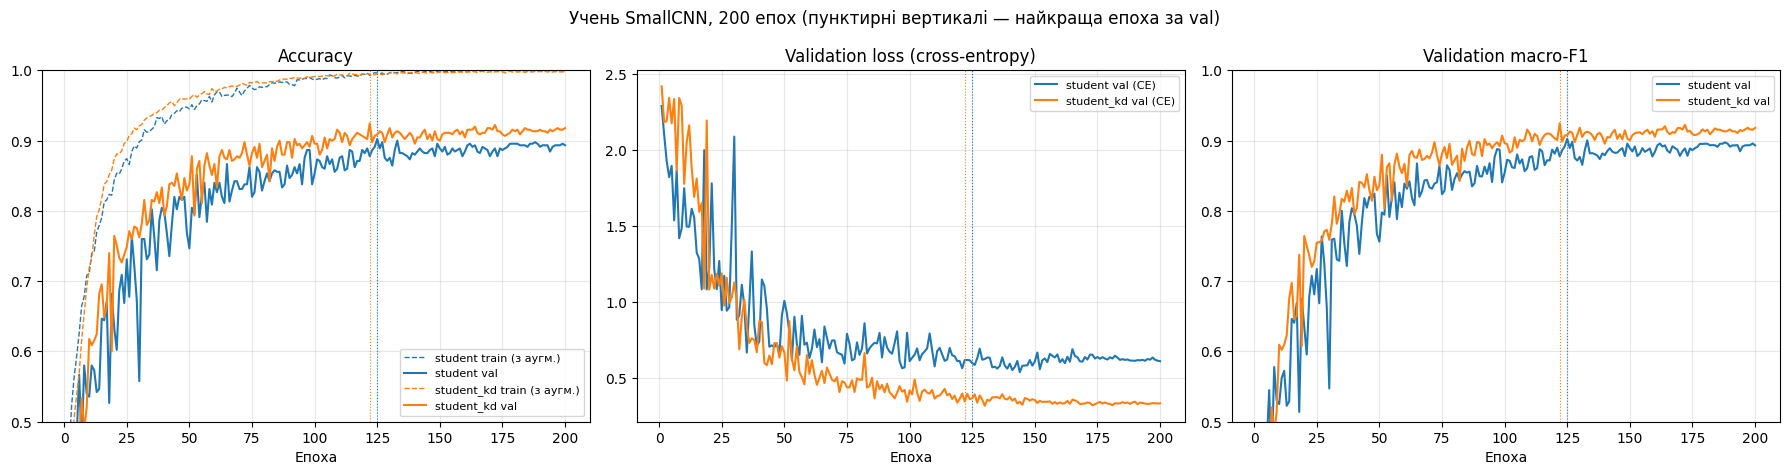

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for (name, h), color in zip(histories.items(), ('tab:blue', 'tab:orange')):
    ep = np.arange(1, len(h['val_acc']) + 1)
    axes[0].plot(ep, h['train_acc'], color=color, ls='--', lw=1, label=f'{name} train (з аугм.)')
    axes[0].plot(ep, h['val_acc'], color=color, label=f'{name} val')
    axes[1].plot(ep, h['val_loss'], color=color, label=f'{name} val (CE)')
    axes[2].plot(ep, h['val_f1'], color=color, label=f'{name} val')
    for ax in axes:
        ax.axvline(h['best_epoch'], color=color, lw=0.8, ls=':')
axes[0].set_ylim(0.5, 1.0)
axes[2].set_ylim(0.5, 1.0)
for ax, t in zip(axes, ('Accuracy', 'Validation loss (cross-entropy)', 'Validation macro-F1')):
    ax.set_title(t); ax.set_xlabel('Епоха'); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.suptitle('Учень SmallCNN, 200 епох (пунктирні вертикалі — найкраща епоха за val)')
plt.tight_layout()
plt.show()

In [13]:
def plateau_epoch(h, tol=0.01):
    # перша епоха, на якій val accuracy вперше опинилась у межах tol від свого максимуму
    best = max(h['val_acc'])
    return next(i + 1 for i, v in enumerate(h['val_acc']) if v >= best - tol)


summary = pd.DataFrame(results).T[['best_epoch', 'train_acc', 'val_acc', 'val_f1', 'test_acc', 'test_f1',
                                   'train-val gap', 'train_time_s']]
summary.insert(1, 'плато (val acc ≥ max − 1 п.п.)', [plateau_epoch(histories[n]) for n in summary.index])
summary.insert(0, 'параметрів', [count_params(MODELS[n]) for n in summary.index])
summary.to_csv(OUT_DIR / 'results_students_200ep.csv')
summary.round(4)

,параметрів,best_epoch,плато (val acc ≥ max − 1 п.п.),train_acc,val_acc,val_f1,test_acc,test_f1,train-val gap,train_time_s
student,1180926,125.0,125,0.9998,0.9022,0.9025,0.9033,0.9026,0.0976,1380.0
student_kd,1180926,122.0,109,0.9991,0.9244,0.9247,0.9017,0.9005,0.0747,2182.0


### Метрики для кожного класу (test)

* **precision** — частка зображень, віднесених до класу, які справді йому належать;
* **recall** — частка зображень класу, розпізнаних правильно, тобто **accuracy класу**;
* **accuracy (one-vs-rest)** — (TP + TN) / N для задачі «клас vs решта» (завжди близька до 1).

20 тестових зображень на клас: зміна recall на 0.05 = одне зображення.

In [14]:
y_test = LABELS[idx['test']].numpy()
test_idx = idx['test']


def per_class_metrics(y_true, y_pred):
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=range(NUM_CLASSES), zero_division=0)
    cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
    tp = np.diag(cm)
    fp, fn = cm.sum(0) - tp, cm.sum(1) - tp
    tn = cm.sum() - tp - fp - fn
    out = pd.DataFrame({'precision': p, 'recall (= accuracy класу)': r, 'f1': f,
                        'accuracy (one-vs-rest)': (tp + tn) / cm.sum()}, index=classes)
    out.loc['macro avg'] = out.mean()
    return out


pc = {name: per_class_metrics(y_test, test_preds[name]) for name in MODELS}
per_class = pd.concat({name: pc[name] for name in MODELS}, axis=1).sort_values(('student', 'f1'))
per_class.to_csv(OUT_DIR / 'per_class_students_200ep.csv')
np.savez(OUT_DIR / 'test_preds_students_200ep.npz', y_test=y_test, test_idx=test_idx, **test_preds)
json.dump(histories, open(OUT_DIR / 'histories_students_200ep.json', 'w'))

(per_class.style.format('{:.3f}')
 .background_gradient(cmap='RdYlGn', vmin=0.4, vmax=1.0,
                      subset=[c for c in per_class.columns if c[1] != 'accuracy (one-vs-rest)']))

## 7. Висновки

_(заповнити після запуску)_
* на якій епосі кожен учень виходить на плато і яка його максимальна val / test accuracy;
* чи дає дистиляція виграш при довгому навчанні, чи лише прискорює збіжність;
* як змінюється розрив train–val до кінця навчання (ознаки перенавчання);
* які класи лишаються найслабшими навіть після 200 епох.